In [2]:
df = pd.read_csv("dataset/netflix_titles.csv")

print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [3]:
print("Rows and Columns:", df.shape)

Rows and Columns: (8807, 12)


In [4]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Welcome to CodeAlpha EDA Project!")
print("All libraries imported successfully!")

Welcome to CodeAlpha EDA Project!
All libraries imported successfully!


In [6]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [7]:
# Fill missing values in director, cast and country

df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")

# Remove rows with missing date_added, rating or duration

df.dropna(subset=["date_added", "rating", "duration"], inplace=True)

# Check missing values again

print(df.isnull().sum())


show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


C:\Users\ankita\AppData\Local\Temp\ipykernel_10308\2224728309.py:9: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["date_added", "rating", "duration"], inplace=True)


In [8]:
type_counts = df["type"].value_counts()

print(type_counts)


type
Movie      6126
TV Show    2664
Name: count, dtype: int64


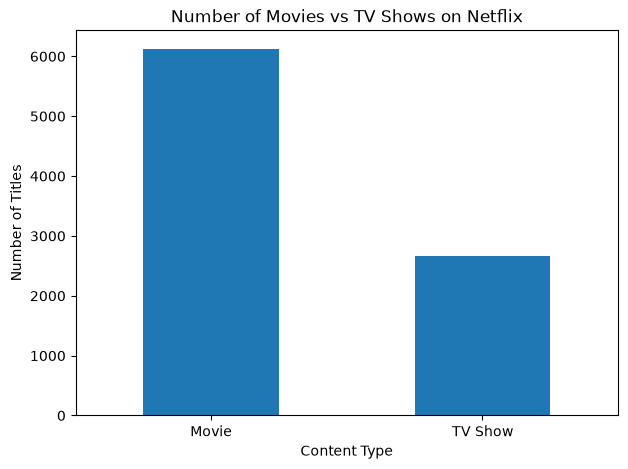

In [9]:
plt.figure(figsize=(7, 5))

type_counts.plot(kind="bar")

plt.title("Number of Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.xticks(rotation=0)
plt.show()

In [10]:
country_counts = df["country"].str.split(", ").explode()

top_countries = country_counts.value_counts().head(10)

print(top_countries)

country
United States     3680
India             1046
Unknown            829
United Kingdom     803
Canada             445
France             393
Japan              316
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64


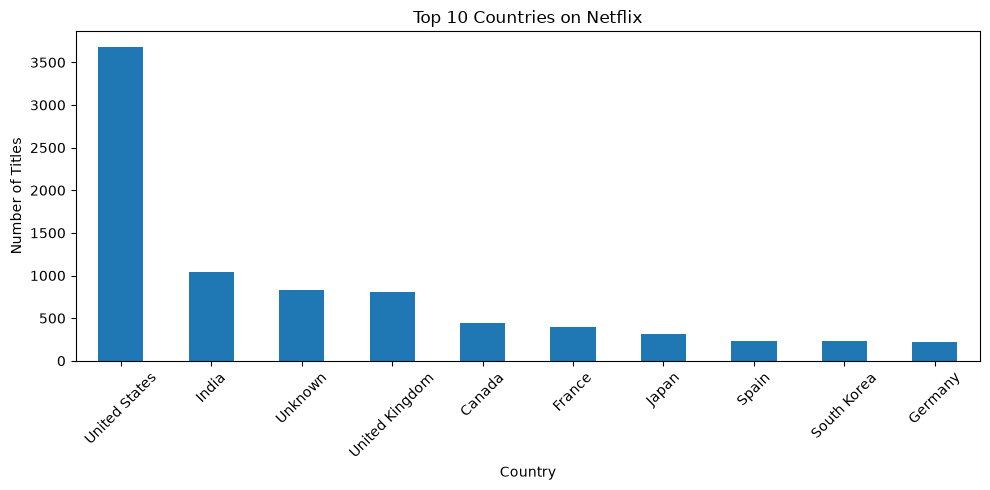

In [11]:
plt.figure(figsize=(10, 5))

top_countries.plot(kind="bar")

plt.title("Top 10 Countries on Netflix")
plt.xlabel("Country")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
year_counts = df["release_year"].value_counts().sort_index()

print(year_counts.tail(15))

release_year
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, dtype: int64


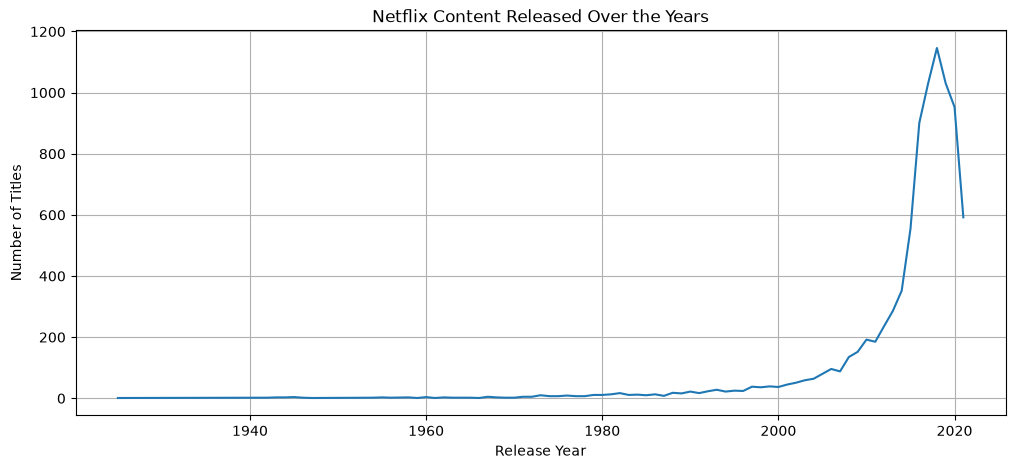

In [13]:
plt.figure(figsize=(12, 5))

year_counts.plot(kind="line")

plt.title("Netflix Content Released Over the Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.grid()
plt.show()

In [14]:
most_content_year = df["release_year"].value_counts().idxmax()

print("Year with most releases:", most_content_year)
print("Number of titles:", df["release_year"].value_counts().max())

Year with most releases: 2018
Number of titles: 1146


In [15]:
genre_counts = df["listed_in"].str.split(", ").explode()

top_genres = genre_counts.value_counts().head(10)

print(top_genres)

listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


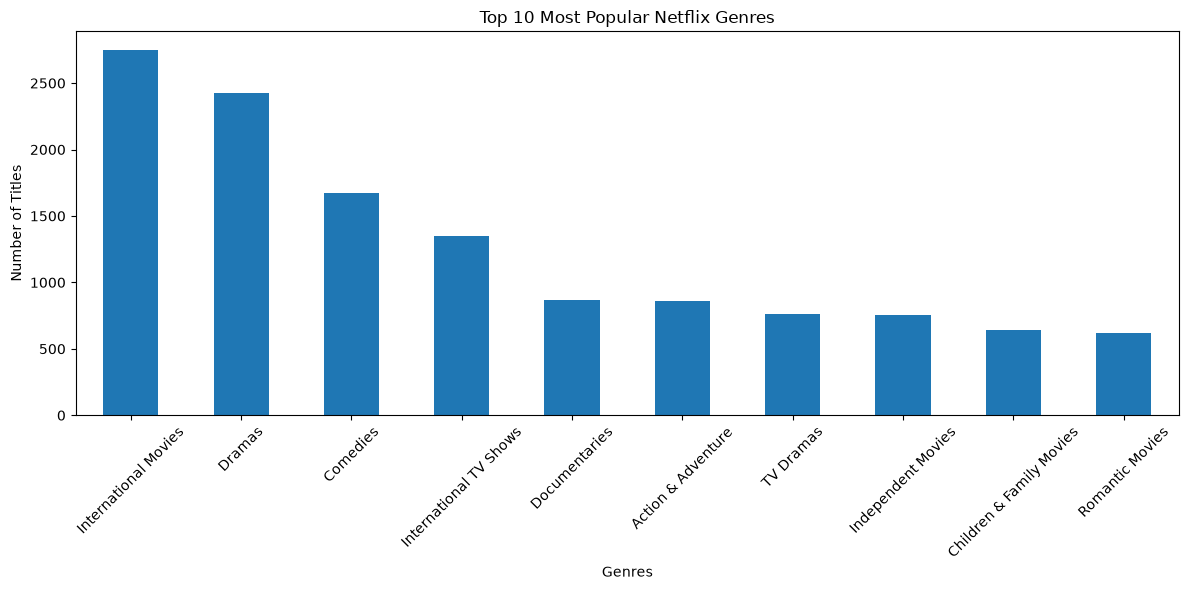

In [16]:
plt.figure(figsize=(12, 6))

top_genres.plot(kind="bar")

plt.title("Top 10 Most Popular Netflix Genres")
plt.xlabel("Genres")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

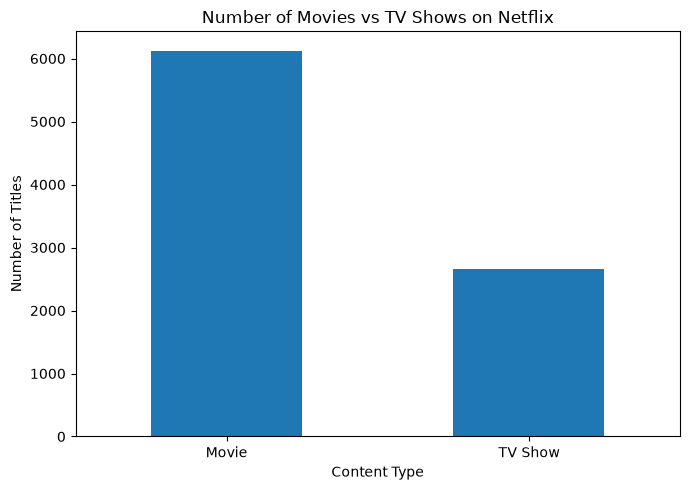

In [17]:
type_counts = df["type"].value_counts()

plt.figure(figsize=(7, 5))
type_counts.plot(kind="bar")

plt.title("Number of Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("charts/content_types.png")
plt.show()

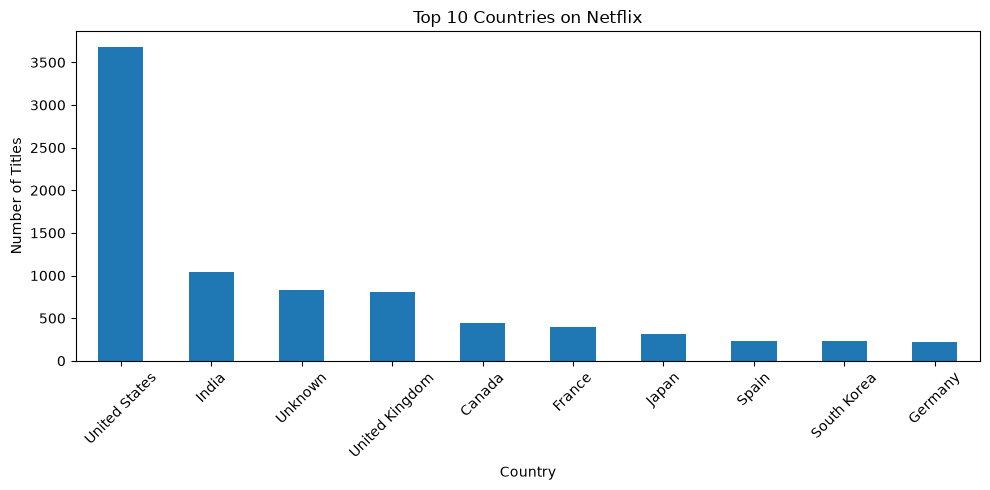

In [18]:
country_counts = df["country"].str.split(", ").explode()
top_countries = country_counts.value_counts().head(10)

plt.figure(figsize=(10, 5))
top_countries.plot(kind="bar")

plt.title("Top 10 Countries on Netflix")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("charts/top_countries.png")
plt.show()

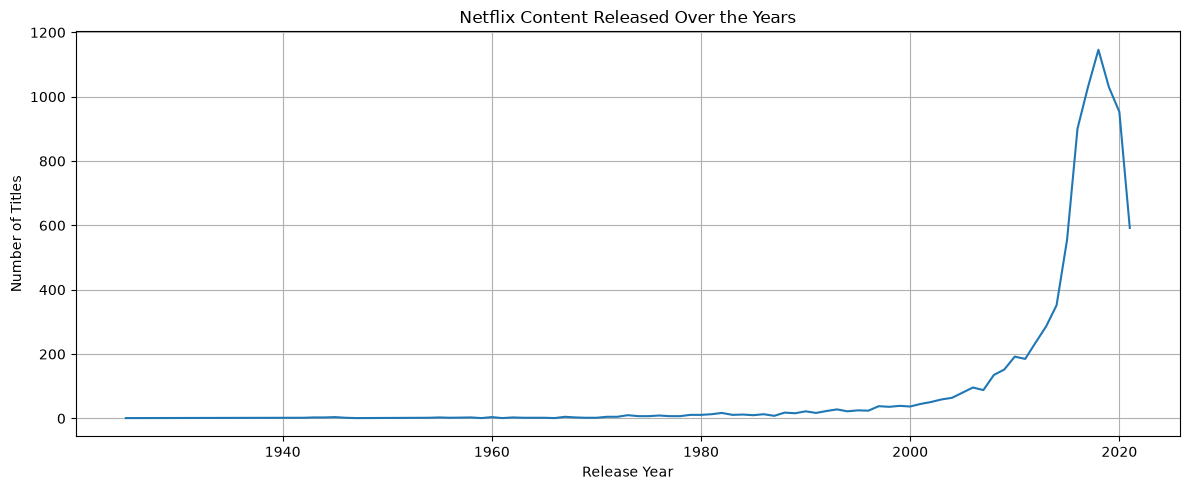

In [19]:
year_counts = df["release_year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
year_counts.plot(kind="line")

plt.title("Netflix Content Released Over the Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid()

plt.tight_layout()
plt.savefig("charts/release_years.png")
plt.show()

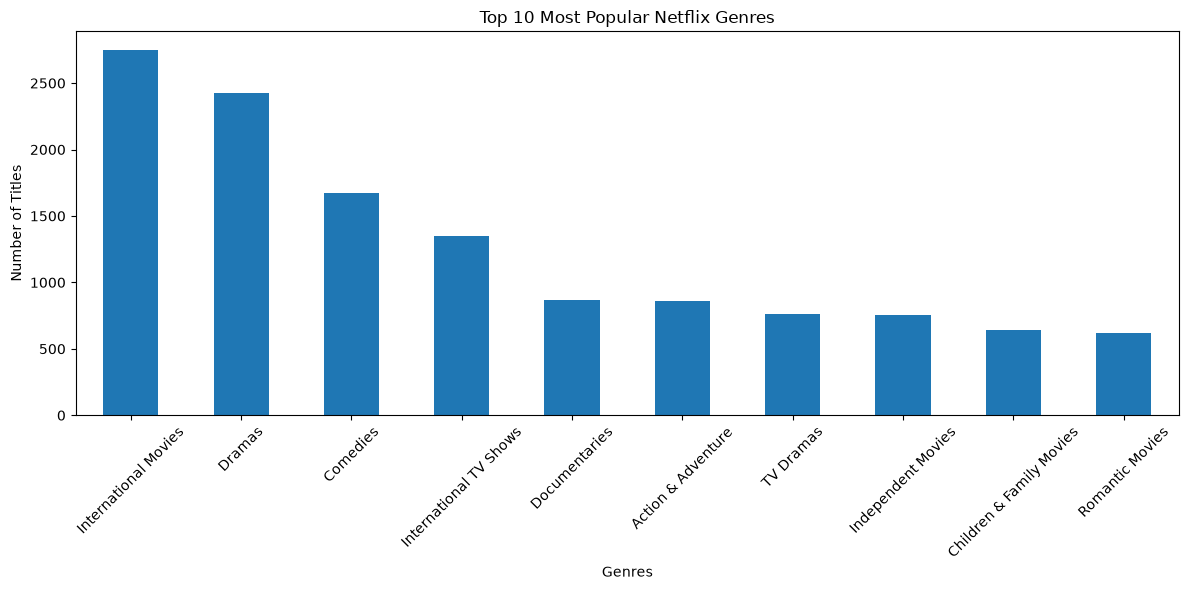

In [20]:
genre_counts = df["listed_in"].str.split(", ").explode()
top_genres = genre_counts.value_counts().head(10)

plt.figure(figsize=(12, 6))
top_genres.plot(kind="bar")

plt.title("Top 10 Most Popular Netflix Genres")
plt.xlabel("Genres")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("charts/top_genres.png")
plt.show()